# 离散序列与时域滤波

从冲激和序列延迟开始，比较记录上一拍输入和记录上一拍输出的两个系统。

## 冲激、阶跃、衰减与周期序列

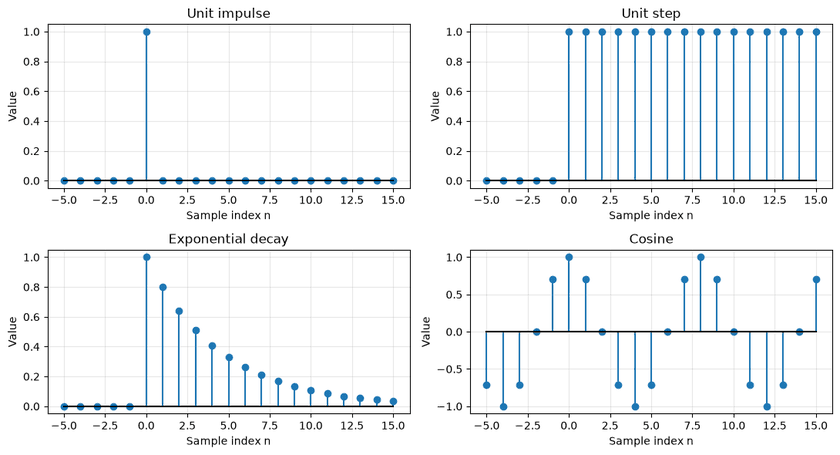

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 显示编号为 -5 到 15 的这一段
n = np.arange(-5, 16)

# 1. 单位冲激：只有 n = 0 时为 1
impulse = (n == 0).astype(float)

# 2. 单位阶跃：n >= 0 时为 1
step = (n >= 0).astype(float)

# 3. 指数衰减：负编号部分由 step 置零
decay = (0.8 ** n) * step

# 4. 余弦序列：每隔 8 个样本重复
wave = np.cos(np.pi * n / 4)

signals = [impulse, step, decay, wave]
titles = ["Unit impulse", "Unit step", "Exponential decay", "Cosine"]

fig, axes = plt.subplots(2, 2, figsize=(11, 6))

for ax, values, title in zip(axes.flat, signals, titles):
    ax.stem(n, values, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("Sample index n")
    ax.set_ylabel("Value")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 补零延迟、循环移位与信号能量

原始数据： [1 2 3 4 5]
补零右移： [0 0 1 2 3]
循环右移： [4 5 1 2 3]


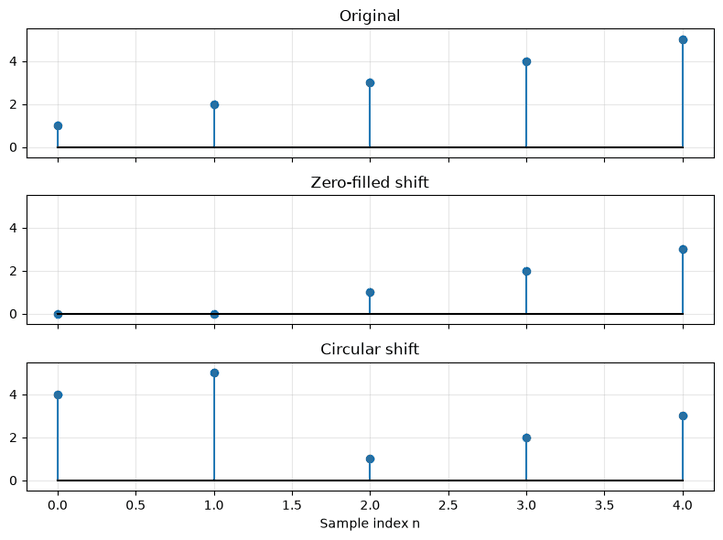

In [2]:
x_demo = np.array([1, 2, 3, 4, 5])
delay = 2

# 零延拓右移，并保留原来的数组长度
y_zero = np.zeros_like(x_demo)
y_zero[delay:] = x_demo[:-delay]

# 循环右移
y_circular = np.roll(x_demo, delay)

print("原始数据：", x_demo)
print("补零右移：", y_zero)
print("循环右移：", y_circular)

# 三张图使用相同的横轴位置
n_demo = np.arange(len(x_demo))

fig, axes = plt.subplots(3, 1, figsize=(8, 6), sharex=True)

for ax, values, title in zip(
    axes,
    [x_demo, y_zero, y_circular],
    ["Original", "Zero-filled shift", "Circular shift"]
):
    ax.stem(n_demo, values, basefmt="k-")
    ax.set_title(title)
    ax.set_ylim(-0.5, 5.5)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Sample index n")
plt.tight_layout()
plt.show()

In [3]:
energy = np.sum(np.abs(x_demo) ** 2)
print(energy)  # 55

mean_square = np.mean(np.abs(x_demo) ** 2)

55


## 两点移动平均怎样处理快慢叠加的信号

In [4]:
import numpy as np
import matplotlib.pyplot as plt


def moving_average_2(x):
    """
    对一维实值信号做两点移动平均。

    计算：
        y[n] = 0.5 * (x[n] + x[n-1])

    初始条件：
        x[-1] = 0

    返回与输入等长的输出数组。
    """
    # 把输入转成浮点数数组
    x = np.asarray(x, dtype=float)

    # 创建输出数组，形状与 x 相同
    y = np.zeros_like(x)

    # 开始之前，上一个输入设为 0
    previous = 0.0

    for n in range(len(x)):
        # 取出当前输入
        current = x[n]

        # 当前输入 + 上一个输入，再乘 0.5
        y[n] = 0.5 * (current + previous)

        # 保存当前输入，供下一轮使用
        previous = current

    return y


x_demo = [1, 4, 2, 7, 3]
y_demo = moving_average_2(x_demo)

print(y_demo)

[0.5 2.5 3.  4.5 5. ]


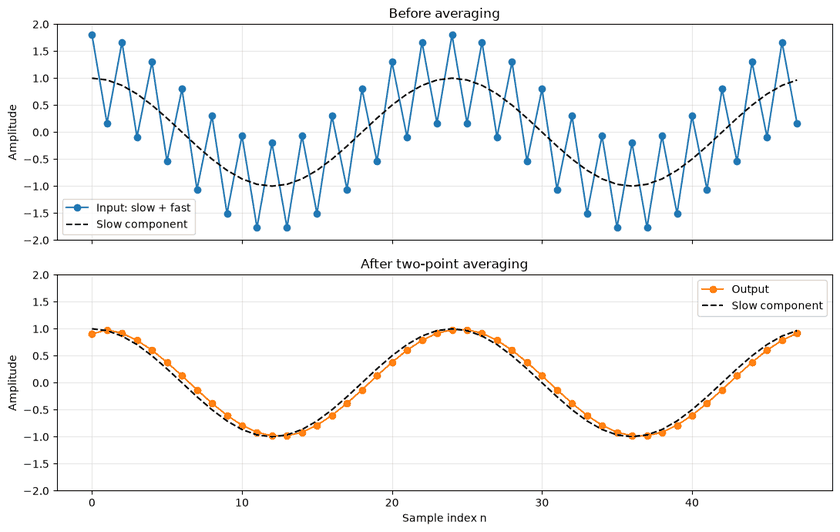

In [5]:
# 48 个采样位置：0, 1, ..., 47
n = np.arange(48)

# 缓慢变化的部分：每 24 个样本一个周期
slow = np.cos(2 * np.pi * n / 24)

# 快速交替的部分：0.8, -0.8, 0.8, -0.8, ...
fast = 0.8 * ((-1.0) ** n)

# 两部分逐点相加
x = slow + fast

# 两点移动平均
y = moving_average_2(x)

# 上下两幅图共享横轴和纵轴范围，方便比较
fig, axes = plt.subplots(
    2, 1,
    figsize=(11, 7),
    sharex=True,
    sharey=True
)

# 处理前
axes[0].plot(
    n, x, "o-",
    color="tab:blue",
    label="Input: slow + fast"
)

axes[0].plot(
    n, slow, "--",
    color="black",
    label="Slow component"
)

axes[0].set_title("Before averaging")

# 处理后
axes[1].plot(
    n, y, "o-",
    color="tab:orange",
    label="Output"
)

axes[1].plot(
    n, slow, "--",
    color="black",
    label="Slow component"
)

axes[1].set_title("After two-point averaging")

for ax in axes:
    ax.set_ylabel("Amplitude")
    ax.set_ylim(-2, 2)
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[1].set_xlabel("Sample index n")

plt.tight_layout()
plt.show()

## 一阶反馈与不同系数的冲激响应

In [6]:
import numpy as np


def feedback_filter(x, alpha):
    """
    处理一维实值输入信号。

    计算规则：
        y[n] = x[n] + alpha * y[n-1]

    初始状态：
        y[-1] = 0

    返回与输入等长的输出数组。
    """
    # 把输入整理成浮点数数组
    x = np.asarray(x, dtype=float)

    # 为全部输出准备存储位置
    y = np.zeros_like(x)

    # 保存上一次输出；开始之前设为 0
    previous_output = 0.0

    # 按顺序处理每一个输入样本
    for i in range(len(x)):
        # 1. 读取当前输入
        current_input = x[i]

        # 2. 计算从旧输出送回来的反馈量
        feedback = alpha * previous_output

        # 3. 当前输入与反馈量相加
        current_output = current_input + feedback

        # 4. 把当前结果写进输出数组
        y[i] = current_output

        # 5. 更新状态，供下一轮使用
        previous_output = current_output

    return y


x_demo = [1, 0, 0, 0, 0, 0]
y_demo = feedback_filter(x_demo, alpha=0.8)

print(y_demo)

[1.      0.8     0.64    0.512   0.4096  0.32768]


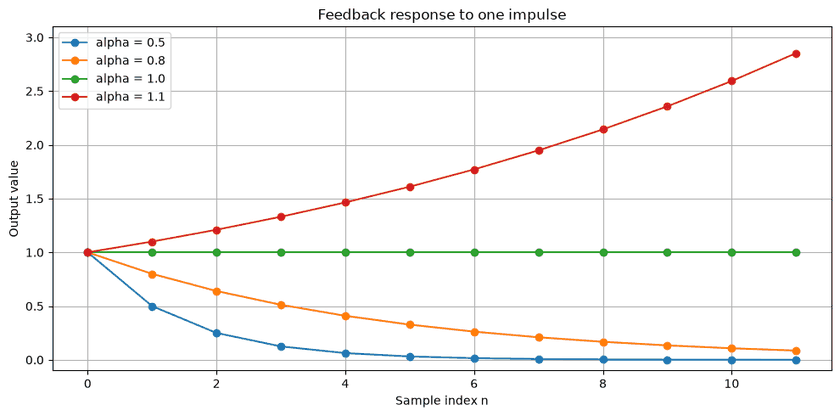

In [7]:
import matplotlib.pyplot as plt

# 创建 12 个时刻的输入，初始全为 0
impulse = np.zeros(12, dtype=float)

# 第一个时刻输入 1，形成单位脉冲
impulse[0] = 1.0

# 横坐标：0, 1, ..., 11
n = np.arange(len(impulse))

# 准备比较的四个反馈系数
alphas = [0.5, 0.8, 1.0, 1.1]

# 创建一张图，其中只有一个绘图区
fig, ax = plt.subplots(figsize=(10, 5))

for alpha in alphas:
    # 使用当前反馈系数，计算完整的一段输出
    output = feedback_filter(impulse, alpha)

    # 把这段输出画到同一个绘图区
    ax.plot(
        n,
        output,
        marker="o",
        linestyle="-",
        label=f"alpha = {alpha}"
    )

ax.set_title("Feedback response to one impulse")
ax.set_xlabel("Sample index n")
ax.set_ylabel("Output value")
ax.set_ylim(-0.1, 3.1)

ax.grid(True)
ax.legend()

plt.tight_layout()
plt.show()

## 多拍延迟反馈的递推与回声

In [8]:
import numpy as np


def feedback_delay(x, alpha, M):
    """
    带 M 个样本延迟的反馈系统。

    计算规则：
        y[n] = x[n] + alpha * y[n-M]

    初始状态：
        n < 0 时，y[n] = 0

    x：一维实值输入
    alpha：反馈系数
    M：延迟的样本数，取正整数
    """
    # 将输入整理成浮点数数组
    x = np.asarray(x, dtype=float)

    # 准备与输入等长的输出数组
    y = np.zeros_like(x)

    # 按顺序计算每一个输出
    for i in range(len(x)):
        current_input = x[i]

        # 最开始的 M 个时刻，还没有对应的历史输出
        if i < M:
            delayed_output = 0.0
        else:
            delayed_output = y[i - M]

        # 历史输出经过倍乘，形成反馈量
        feedback = alpha * delayed_output

        # 当前输入与反馈量相加
        current_output = current_input + feedback

        # 保存本次输出
        y[i] = current_output

    return y

In [9]:
# 最开始输入的小波形
block = np.array([1, 0.5, -1], dtype=float)

# 小波形有几个样本，就延迟几个样本
M_demo = len(block)

# 一共观察 4 组，每组 M_demo 个样本
x_demo = np.zeros(4 * M_demo, dtype=float)

# 只在开头放入这段小波形，其余输入保持为 0
x_demo[:M_demo] = block

# 计算反馈系统的输出
y_demo = feedback_delay(
    x_demo,
    alpha=0.8,
    M=M_demo
)

print("输入：", x_demo)
print("输出：", y_demo)

输入： [ 1.   0.5 -1.   0.   0.   0.   0.   0.   0.   0.   0.   0. ]
输出： [ 1.     0.5   -1.     0.8    0.4   -0.8    0.64   0.32  -0.64   0.512
  0.256 -0.512]


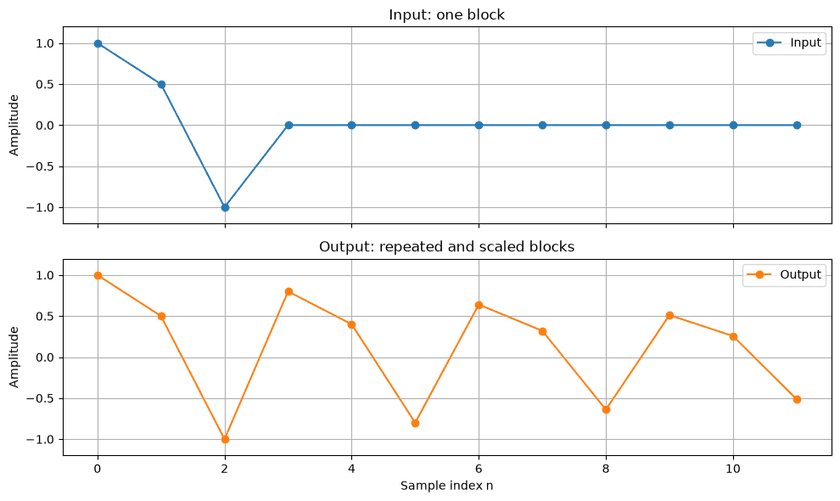

In [10]:
import matplotlib.pyplot as plt

# 为每个样本生成横坐标
n_demo = np.arange(len(x_demo))

# 创建上下两个绘图区，并共享坐标尺度
fig, axes = plt.subplots(
    2, 1,
    figsize=(10, 6),
    sharex=True,
    sharey=True
)

# 上图：输入
axes[0].plot(
    n_demo,
    x_demo,
    marker="o",
    linestyle="-",
    color="tab:blue",
    label="Input"
)

axes[0].set_title("Input: one block")

# 下图：输出
axes[1].plot(
    n_demo,
    y_demo,
    marker="o",
    linestyle="-",
    color="tab:orange",
    label="Output"
)

axes[1].set_title("Output: repeated and scaled blocks")

# 对两个绘图区分别设置相同的显示属性
for ax in axes:
    ax.set_ylabel("Amplitude")
    ax.set_ylim(-1.2, 1.2)
    ax.grid(True)
    ax.legend()

axes[1].set_xlabel("Sample index n")

plt.tight_layout()
plt.show()

## 用衰减回路合成两秒音频

In [11]:
from IPython.display import Audio, display

# 每秒播放的样本数
fs = 8000

# 声音持续 2 秒
duration = 2.0

# 反馈延迟：一圈 40 个样本
M_audio = 40

# 每绕完一圈，幅度乘以 0.99
alpha_audio = 0.99

# 整段声音需要的样本数
N = int(fs * duration)

# 一圈内部的样本编号：0, 1, ..., 39
k = np.arange(M_audio)

# 创建一个幅度为 0.5、长度为 40 的正弦周期
initial_wave = 0.5 * np.sin(2 * np.pi * k / M_audio)

# 输入只在最开始的一圈有值，后面都为 0
excitation = np.zeros(N, dtype=float)
excitation[:M_audio] = initial_wave

# 通过延迟反馈，生成整段声音
audio_signal = feedback_delay(
    excitation,
    alpha=alpha_audio,
    M=M_audio
)

print("一圈的时间：", M_audio / fs, "秒")
print("每秒重复次数：", fs / M_audio)

# 在 Jupyter 中显示音频播放器
display(
    Audio(
        audio_signal,
        rate=fs,
        normalize=False
    )
)

一圈的时间： 0.005 秒
每秒重复次数： 200.0


2 秒合成信号已生成。运行本格可播放。